# 1. Data

## 1.1 Make Data

In [1]:
import sklearn
from sklearn.datasets import make_circles

In [2]:
n_samples = 1000
RANDOM_SEED = 42

# make a big circle containing a small circle in 2D
# toy dataset
X, y = make_circles(n_samples,
                 noise=0.03,
                 random_state=RANDOM_SEED)
print(f"X shape: {X.shape}, y shape: {y.shape}")
print(f"fist 5 samples of X:\n{X[:5]}")
print(f"fist 5 samples of y:\n{y[:5]}")

X shape: (1000, 2), y shape: (1000,)
fist 5 samples of X:
[[ 0.75424625  0.23148074]
 [-0.75615888  0.15325888]
 [-0.81539193  0.17328203]
 [-0.39373073  0.69288277]
 [ 0.44220765 -0.89672343]]
fist 5 samples of y:
[1 1 1 1 0]


In [3]:
# look at the data
import pandas as pd
circles = pd.DataFrame({"X1": X[:, 0],
                        "X2": X[:, 1],
                        "label": y})
circles.head(10)

,X1,X2,label
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0
5,-0.479646,0.676435,1
6,-0.013648,0.803349,1
7,0.771513,0.147760,1
8,-0.169322,-0.793456,1
9,-0.121486,1.021509,0


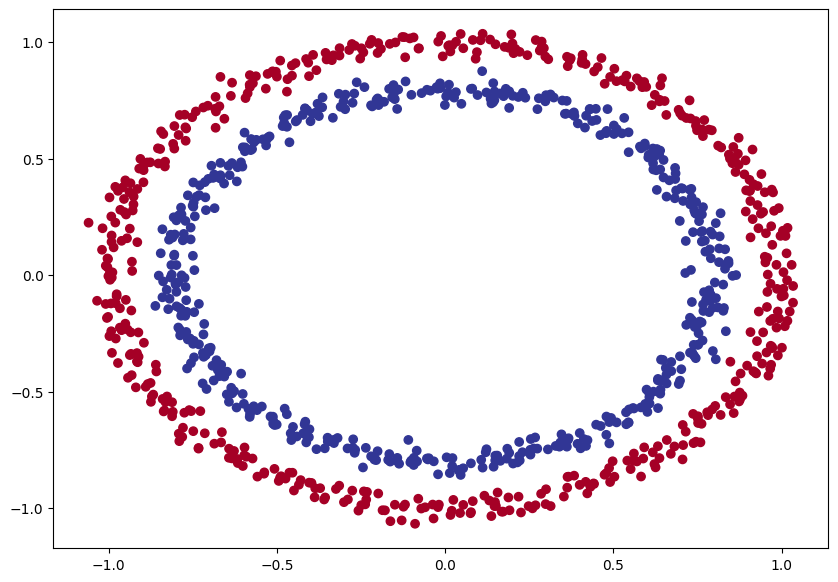

In [4]:
# visualize
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 7))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu)

## 1.2 Turn data into tensors and create training and testing splits

In [5]:
import torch
torch.__version__

'2.12.0+cu126'

In [6]:
# turn data into tensors
X = torch.from_numpy(X).type(torch.float32)
y = torch.from_numpy(y).type(torch.float32)

X[:5], y[:5]

(tensor([[ 0.7542,  0.2315],
         [-0.7562,  0.1533],
         [-0.8154,  0.1733],
         [-0.3937,  0.6929],
         [ 0.4422, -0.8967]]),
 tensor([1., 1., 1., 1., 0.]))

In [7]:
# split datasets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_SEED)
len(X_train), len(X_test), len(y_train), len(y_train)

(800, 200, 800, 800)

## 1.3 device agnostic code

In [8]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

# 2. Create a model

In [9]:
from torch import nn
class CircleModelV0(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_layer1 = nn.Linear(in_features=2, out_features=5)
        self.linear_layer2 = nn.Linear(in_features=5, out_features=1)
        
    def forward(self, x:torch.Tensor) -> torch.Tensor:
        return self.linear_layer2(self.linear_layer1(x))

model_0 = CircleModelV0().to(device)
model_0

CircleModelV0(
  (linear_layer1): Linear(in_features=2, out_features=5, bias=True)
  (linear_layer2): Linear(in_features=5, out_features=1, bias=True)
)

In [10]:
# simpler way to create a model
# 虽然简单, 但只适用于 简单的一层传一层. 可以和上面的创建方法一起使用(__init__里)
model_0 = nn.Sequential(
    nn.Linear(in_features=2, out_features=5),
    nn.Linear(in_features=5, out_features=1)
).to(device)
model_0

Sequential(
  (0): Linear(in_features=2, out_features=5, bias=True)
  (1): Linear(in_features=5, out_features=1, bias=True)
)

In [11]:
# Select a Optimizer and Loss Function
loss_fn = nn.BCEWithLogitsLoss() # Sigmoid + Binary Cross Entropy(BCE), but more numerically stable
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.01)

In [12]:
# Caculate Acc
def accuracy_fn(y_true, y_pred):
    """
    acc = TP / (TP + TN) * 100
    """
    correct = torch.eq(y_true, y_pred).sum().item()
    return (correct / len(y_pred)) * 100

# 3. Train Model

## 3.1 模型的结果
对于classification, 模型的raw result 是 logits(神经网络最后一层未经过激活函数（softmax/sigmoid）的原始输出分数)

如果我们需要得到最终结果, 需要:

- `logits` -> `predictions` -> `labels`

其中
1. `logits` -> `prediction` 需要使用激活函数 sigmoid(二分类) / softmax(多分类)
2. `prediction` -> `labels` 需要通过一个阈值判断, 一般用 `torch.round()`既可

In [13]:
# 取前五组数据测试一下
# logits(raw result)
model_0.eval()
with torch.inference_mode():
    logits = model_0(X_test.to(device)[:5])
logits

tensor([[0.2463],
        [0.2149],
        [0.2849],
        [0.2356],
        [0.2155]], device='cuda:0')

In [14]:
# logits -> predictions
y_pred_probs = torch.sigmoid(logits)
y_pred_probs

tensor([[0.5613],
        [0.5535],
        [0.5707],
        [0.5586],
        [0.5537]], device='cuda:0')

In [15]:
y_preds = torch.round(y_pred_probs)
y_preds

tensor([[1.],
        [1.],
        [1.],
        [1.],
        [1.]], device='cuda:0')

In [16]:
# 一次性走完上述流程：
y_preds_once = torch.round(torch.sigmoid(model_0(X_test.to(device))[:5]))
y_preds_once == y_preds

tensor([[True],
        [True],
        [True],
        [True],
        [True]], device='cuda:0')

## 3.2 Training and Testing Loop

In [ ]:
RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed(RANDOM_SEED)

epochs = 100

X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

# training loop
for epoch in range(epochs):
    ### training
    model_0.train()
    # 1. forward pass
    train_logits = model_0(X_train).squeeze()
    train_pred = torch.round(torch.sigmoid(train_logits))
    
    # 2. caculate loss
    train_loss = loss_fn(train_logits, y_train)
    train_acc = accuracy_fn(y_train, train_pred)
    
    # 3. zero grad
    optimizer.zero_grad()
    
    # 4. back propagation
    train_loss.backward()
    
    # 5. step
    optimizer.step()
    
    ### testing
    model_0.eval()
    with torch.inference_mode():
        # 1. forward pass
        test_logits = model_0(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))
        
        # 2. caculate loss
        test_loss = loss_fn(test_logits, y_test)
        test_acc = accuracy_fn(y_test, test_pred)
    
    ### printing
    if epoch % 10 == 0:
        print(f"epoch: {epoch} | loss: {train_loss:.5f} ; acc: {train_acc:.2f}% | test loss: {test_loss:.5f} ; test acc: {test_acc:.2f}%")
    

epoch: 0 | loss: 0.70034 ; acc: 50.00% | test loss: 0.69886 ; test acc: 50.00%
epoch: 10 | loss: 0.69954 ; acc: 50.00% | test loss: 0.69811 ; test acc: 50.00%
epoch: 20 | loss: 0.69884 ; acc: 50.00% | test loss: 0.69745 ; test acc: 50.00%
epoch: 30 | loss: 0.69822 ; acc: 50.00% | test loss: 0.69687 ; test acc: 50.00%
epoch: 40 | loss: 0.69767 ; acc: 50.00% | test loss: 0.69636 ; test acc: 50.00%
epoch: 50 | loss: 0.69719 ; acc: 50.00% | test loss: 0.69592 ; test acc: 50.00%
epoch: 60 | loss: 0.69677 ; acc: 50.00% | test loss: 0.69553 ; test acc: 50.00%
epoch: 70 | loss: 0.69639 ; acc: 50.00% | test loss: 0.69519 ; test acc: 50.00%
epoch: 80 | loss: 0.69606 ; acc: 50.00% | test loss: 0.69489 ; test acc: 50.00%
epoch: 90 | loss: 0.69577 ; acc: 50.00% | test loss: 0.69464 ; test acc: 50.00%
epoch: 100 | loss: 0.69551 ; acc: 50.00% | test loss: 0.69441 ; test acc: 50.00%
epoch: 110 | loss: 0.69529 ; acc: 50.00% | test loss: 0.69422 ; test acc: 50.00%
epoch: 120 | loss: 0.69509 ; acc: 50.00

In [18]:
from helper_functions import plot_decision_boundary, plot_predictions

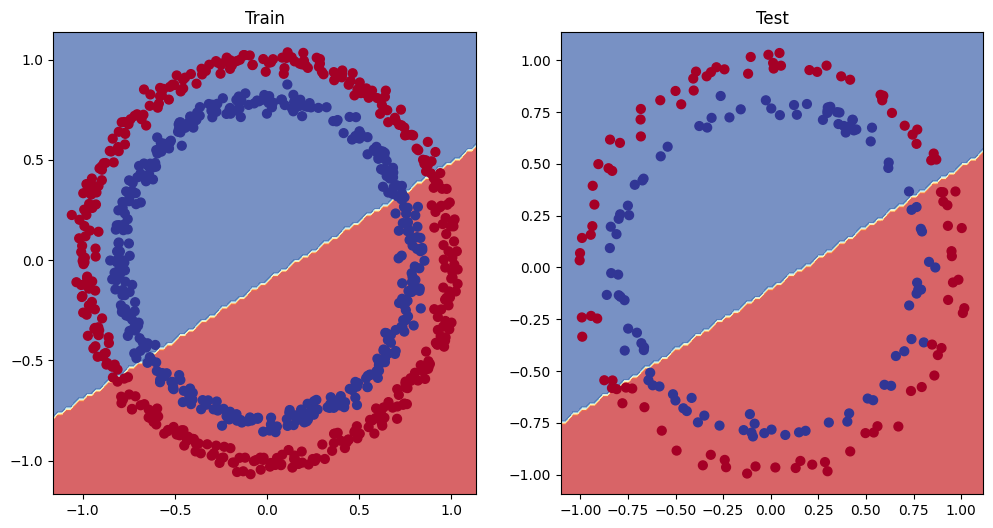

In [19]:
plt.figure(figsize =(12, 6))
plt.subplot(1, 2, 1) # rows, cols, index
plt.title("Train")
plot_decision_boundary(model_0, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_0, X_test, y_test)

## 3.3 Improve Model
1. Add Layers-添加层数
2. Add Hidden Units-添加隐藏层的节点数
3. Adjust Learning Rate-调整学习率
4. Fit for longer-训练更久
5. Change Loss Function-修改损失函数
6. Change Activation Function-修改激活函数
7. Change Optimizer-修改Optimizer

In [ ]:
# 1. add layer
# 2. add hidden units
# 3. lr减小
# 4. 训练更久
# 5. 修改optimizer
model_1 = nn.Sequential(
    nn.Linear(in_features=2, out_features=10),
    nn.Linear(in_features=10, out_features=10),
    nn.Linear(in_features=10, out_features=1)
).to(device)

optimizer = torch.optim.Adam(params=model_1.parameters(), lr=0.001)

epochs = 1000

# training loop
for epoch in range(epochs):
    ### training
    model_1.train()
    # 1. forward pass
    train_logits = model_1(X_train).squeeze()
    train_pred = torch.round(torch.sigmoid(train_logits))
    
    # 2. caculate loss
    train_loss = loss_fn(train_logits, y_train)
    train_acc = accuracy_fn(y_train, train_pred)
    
    # 3. zero grad
    optimizer.zero_grad()
    
    # 4. back propagation
    train_loss.backward()
    
    # 5. step
    optimizer.step()
    
    ### testing
    model_1.eval()
    with torch.inference_mode():
        # 1. forward pass
        test_logits = model_1(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))
        
        # 2. caculate loss
        test_loss = loss_fn(test_logits, y_test)
        test_acc = accuracy_fn(y_test, test_pred)
    
    ### printing
    if epoch % 100 == 0:
        print(f"epoch: {epoch} | loss: {train_loss:.5f} ; acc: {train_acc:.2f}% | test loss: {test_loss:.5f} ; test acc: {test_acc:.2f}%")
    

epoch: 0 | loss: 0.69396 ; acc: 50.88% | test loss: 0.69264 ; test acc: 50.00%
epoch: 100 | loss: 0.69298 ; acc: 51.12% | test loss: 0.69466 ; test acc: 45.50%
epoch: 200 | loss: 0.69298 ; acc: 51.00% | test loss: 0.69468 ; test acc: 46.00%
epoch: 300 | loss: 0.69298 ; acc: 51.00% | test loss: 0.69468 ; test acc: 46.00%
epoch: 400 | loss: 0.69298 ; acc: 51.00% | test loss: 0.69468 ; test acc: 46.00%
epoch: 500 | loss: 0.69298 ; acc: 51.00% | test loss: 0.69468 ; test acc: 46.00%
epoch: 600 | loss: 0.69298 ; acc: 51.00% | test loss: 0.69468 ; test acc: 46.00%
epoch: 700 | loss: 0.69298 ; acc: 51.00% | test loss: 0.69468 ; test acc: 46.00%
epoch: 800 | loss: 0.69298 ; acc: 51.00% | test loss: 0.69468 ; test acc: 46.00%
epoch: 900 | loss: 0.69298 ; acc: 51.00% | test loss: 0.69468 ; test acc: 46.00%


可以看到更改上述 超参数 并没有对模型性能有提升

在该数据集上, 模型似乎什么都学不到

那么在之前使用的线性数据集上, 该模型能学到东西吗?(分析一个large problem的问题时, 可以从一个smaller problem入手)

In [32]:
weight = 0.3
bias = 0.8

X_linear = torch.arange(0, 1, 0.02).unsqueeze(dim=1)
y_linear = weight * X_linear + bias
X_lin_train, X_lin_test, y_lin_train, y_lin_test = train_test_split(X_linear, y_linear, test_size=0.2, random_state=RANDOM_SEED)

X_lin_train = X_lin_train.to(device)
X_lin_test = X_lin_test.to(device)
y_lin_train = y_lin_train.to(device)
y_lin_test = y_lin_test.to(device)

model_1 = nn.Sequential(
    nn.Linear(in_features=1, out_features=10),
    nn.Linear(in_features=10, out_features=10),
    nn.Linear(in_features=10, out_features=1)
).to(device)

loss_fn = nn.L1Loss()
optimizer = torch.optim.Adam(params=model_1.parameters(), lr=0.01)

epochs = 100

for epoch in range(epochs):
    ### training
    model_1.train()
    # 1. forward pass
    train_pred = model_1(X_lin_train)
    
    # 2. caculate loss
    train_loss = loss_fn(train_pred, y_lin_train)
    
    # 3. zero grad
    optimizer.zero_grad()
    
    # 4. back propagation
    train_loss.backward()
    
    # 5. step
    optimizer.step()
    
    ### testing
    model_1.eval()
    with torch.inference_mode():
        # 1. forward pass
        test_pred = model_1(X_lin_test)
        
        # 2. caculate loss
        test_loss = loss_fn(test_pred, y_lin_test)
    
    ### printing
    if epoch % 10 == 0:
        print(f"epoch: {epoch} | loss: {train_loss:.5f} | test loss: {test_loss:.5f}")

epoch: 0 | loss: 1.12036 | test loss: 1.02535
epoch: 10 | loss: 0.19524 | test loss: 0.28657
epoch: 20 | loss: 0.14510 | test loss: 0.12416
epoch: 30 | loss: 0.02736 | test loss: 0.02076
epoch: 40 | loss: 0.00481 | test loss: 0.02889
epoch: 50 | loss: 0.03199 | test loss: 0.03872
epoch: 60 | loss: 0.01167 | test loss: 0.01754
epoch: 70 | loss: 0.01893 | test loss: 0.00525
epoch: 80 | loss: 0.01194 | test loss: 0.00300
epoch: 90 | loss: 0.00436 | test loss: 0.00384


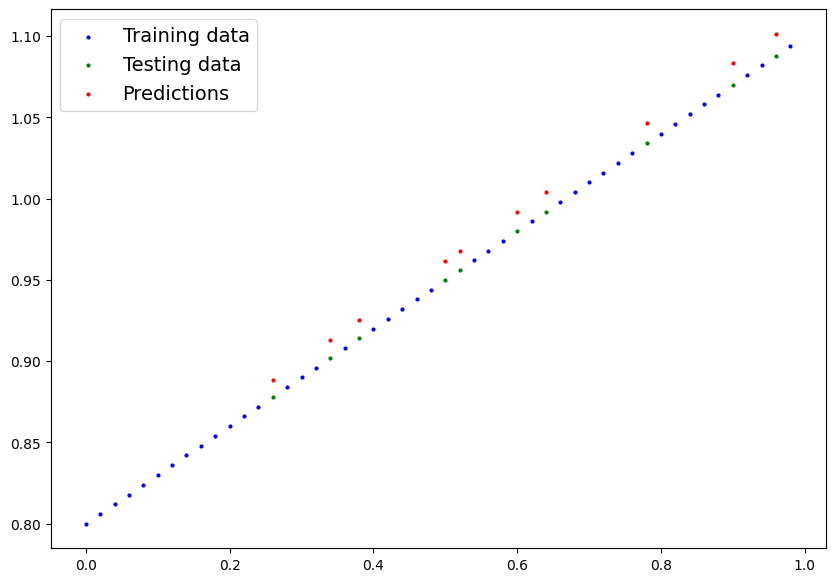

In [35]:
model_1.eval()
with torch.inference_mode():
    predictions = model_1(X_lin_test)

plot_predictions(X_lin_train.cpu(), y_lin_train.cpu(), X_lin_test.cpu(), y_lin_test.cpu(), predictions.cpu())

从结果可以看出, 模型确实能学到一些东西

实际上, 模型缺少了Non-Linear Layer, 因此只能学习到线性的规律

## 3.4 Build a Model with Non-Linear Layer

In [47]:
class CircleModelV2(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=8)
        self.layer_2 = nn.Linear(in_features=8, out_features=8)
        self.layer_3 = nn.Linear(in_features=8, out_features=1)
        self.relu = nn.ReLU()
    
    def forward(self, x: torch.Tensor) -> torch.Tensor :
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))

In [52]:
model_2 = CircleModelV2().to(device)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(params=model_2.parameters(), lr=0.01)

In [53]:
torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed(RANDOM_SEED)

epochs = 100

for epoch in range(epochs):
    model_2.train()
    train_logits = model_2(X_train).squeeze()
    train_preds = torch.round(torch.sigmoid(train_logits))
    
    train_loss = loss_fn(train_logits, y_train)
    train_acc = accuracy_fn(y_train, train_preds)
    
    optimizer.zero_grad()
    
    train_loss.backward()
        
    optimizer.step()
    
    model_2.eval()
    with torch.inference_mode():
        test_logits = model_2(X_test).squeeze()
        test_preds = torch.round(torch.sigmoid(test_logits))
        test_loss = loss_fn(test_logits, y_test)
        test_acc = accuracy_fn(y_test, test_preds)

    if epoch % 10 == 0:
        print(f"epoch: {epoch} | loss: {train_loss:.5f} ; acc: {train_acc:.2f}% | test loss: {test_loss:.5f} ; test acc: {test_acc:.2f}%")

epoch: 0 | loss: 0.69185 ; acc: 54.87% | test loss: 0.69148 ; test acc: 61.00%
epoch: 10 | loss: 0.68363 ; acc: 67.00% | test loss: 0.68405 ; test acc: 68.50%
epoch: 20 | loss: 0.66929 ; acc: 71.88% | test loss: 0.67100 ; test acc: 71.50%
epoch: 30 | loss: 0.63982 ; acc: 77.25% | test loss: 0.64228 ; test acc: 77.00%
epoch: 40 | loss: 0.58892 ; acc: 86.25% | test loss: 0.59505 ; test acc: 85.50%
epoch: 50 | loss: 0.50570 ; acc: 95.88% | test loss: 0.51908 ; test acc: 95.50%
epoch: 60 | loss: 0.39932 ; acc: 97.88% | test loss: 0.41732 ; test acc: 97.50%
epoch: 70 | loss: 0.28810 ; acc: 99.12% | test loss: 0.31230 ; test acc: 98.50%
epoch: 80 | loss: 0.19226 ; acc: 99.38% | test loss: 0.22232 ; test acc: 100.00%
epoch: 90 | loss: 0.12312 ; acc: 100.00% | test loss: 0.15544 ; test acc: 100.00%


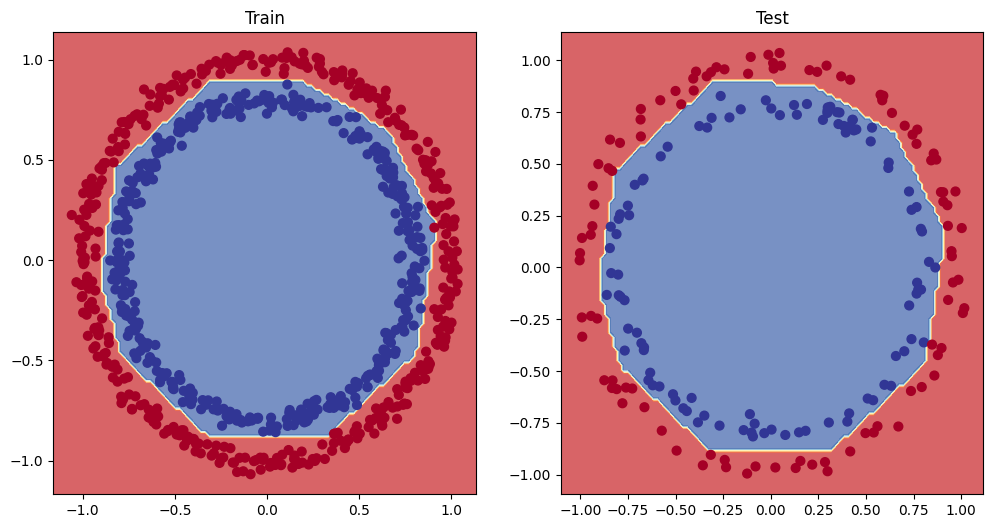

In [54]:
plt.figure(figsize =(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_2, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_2, X_test, y_test)